# Summary fig (Fig 2)

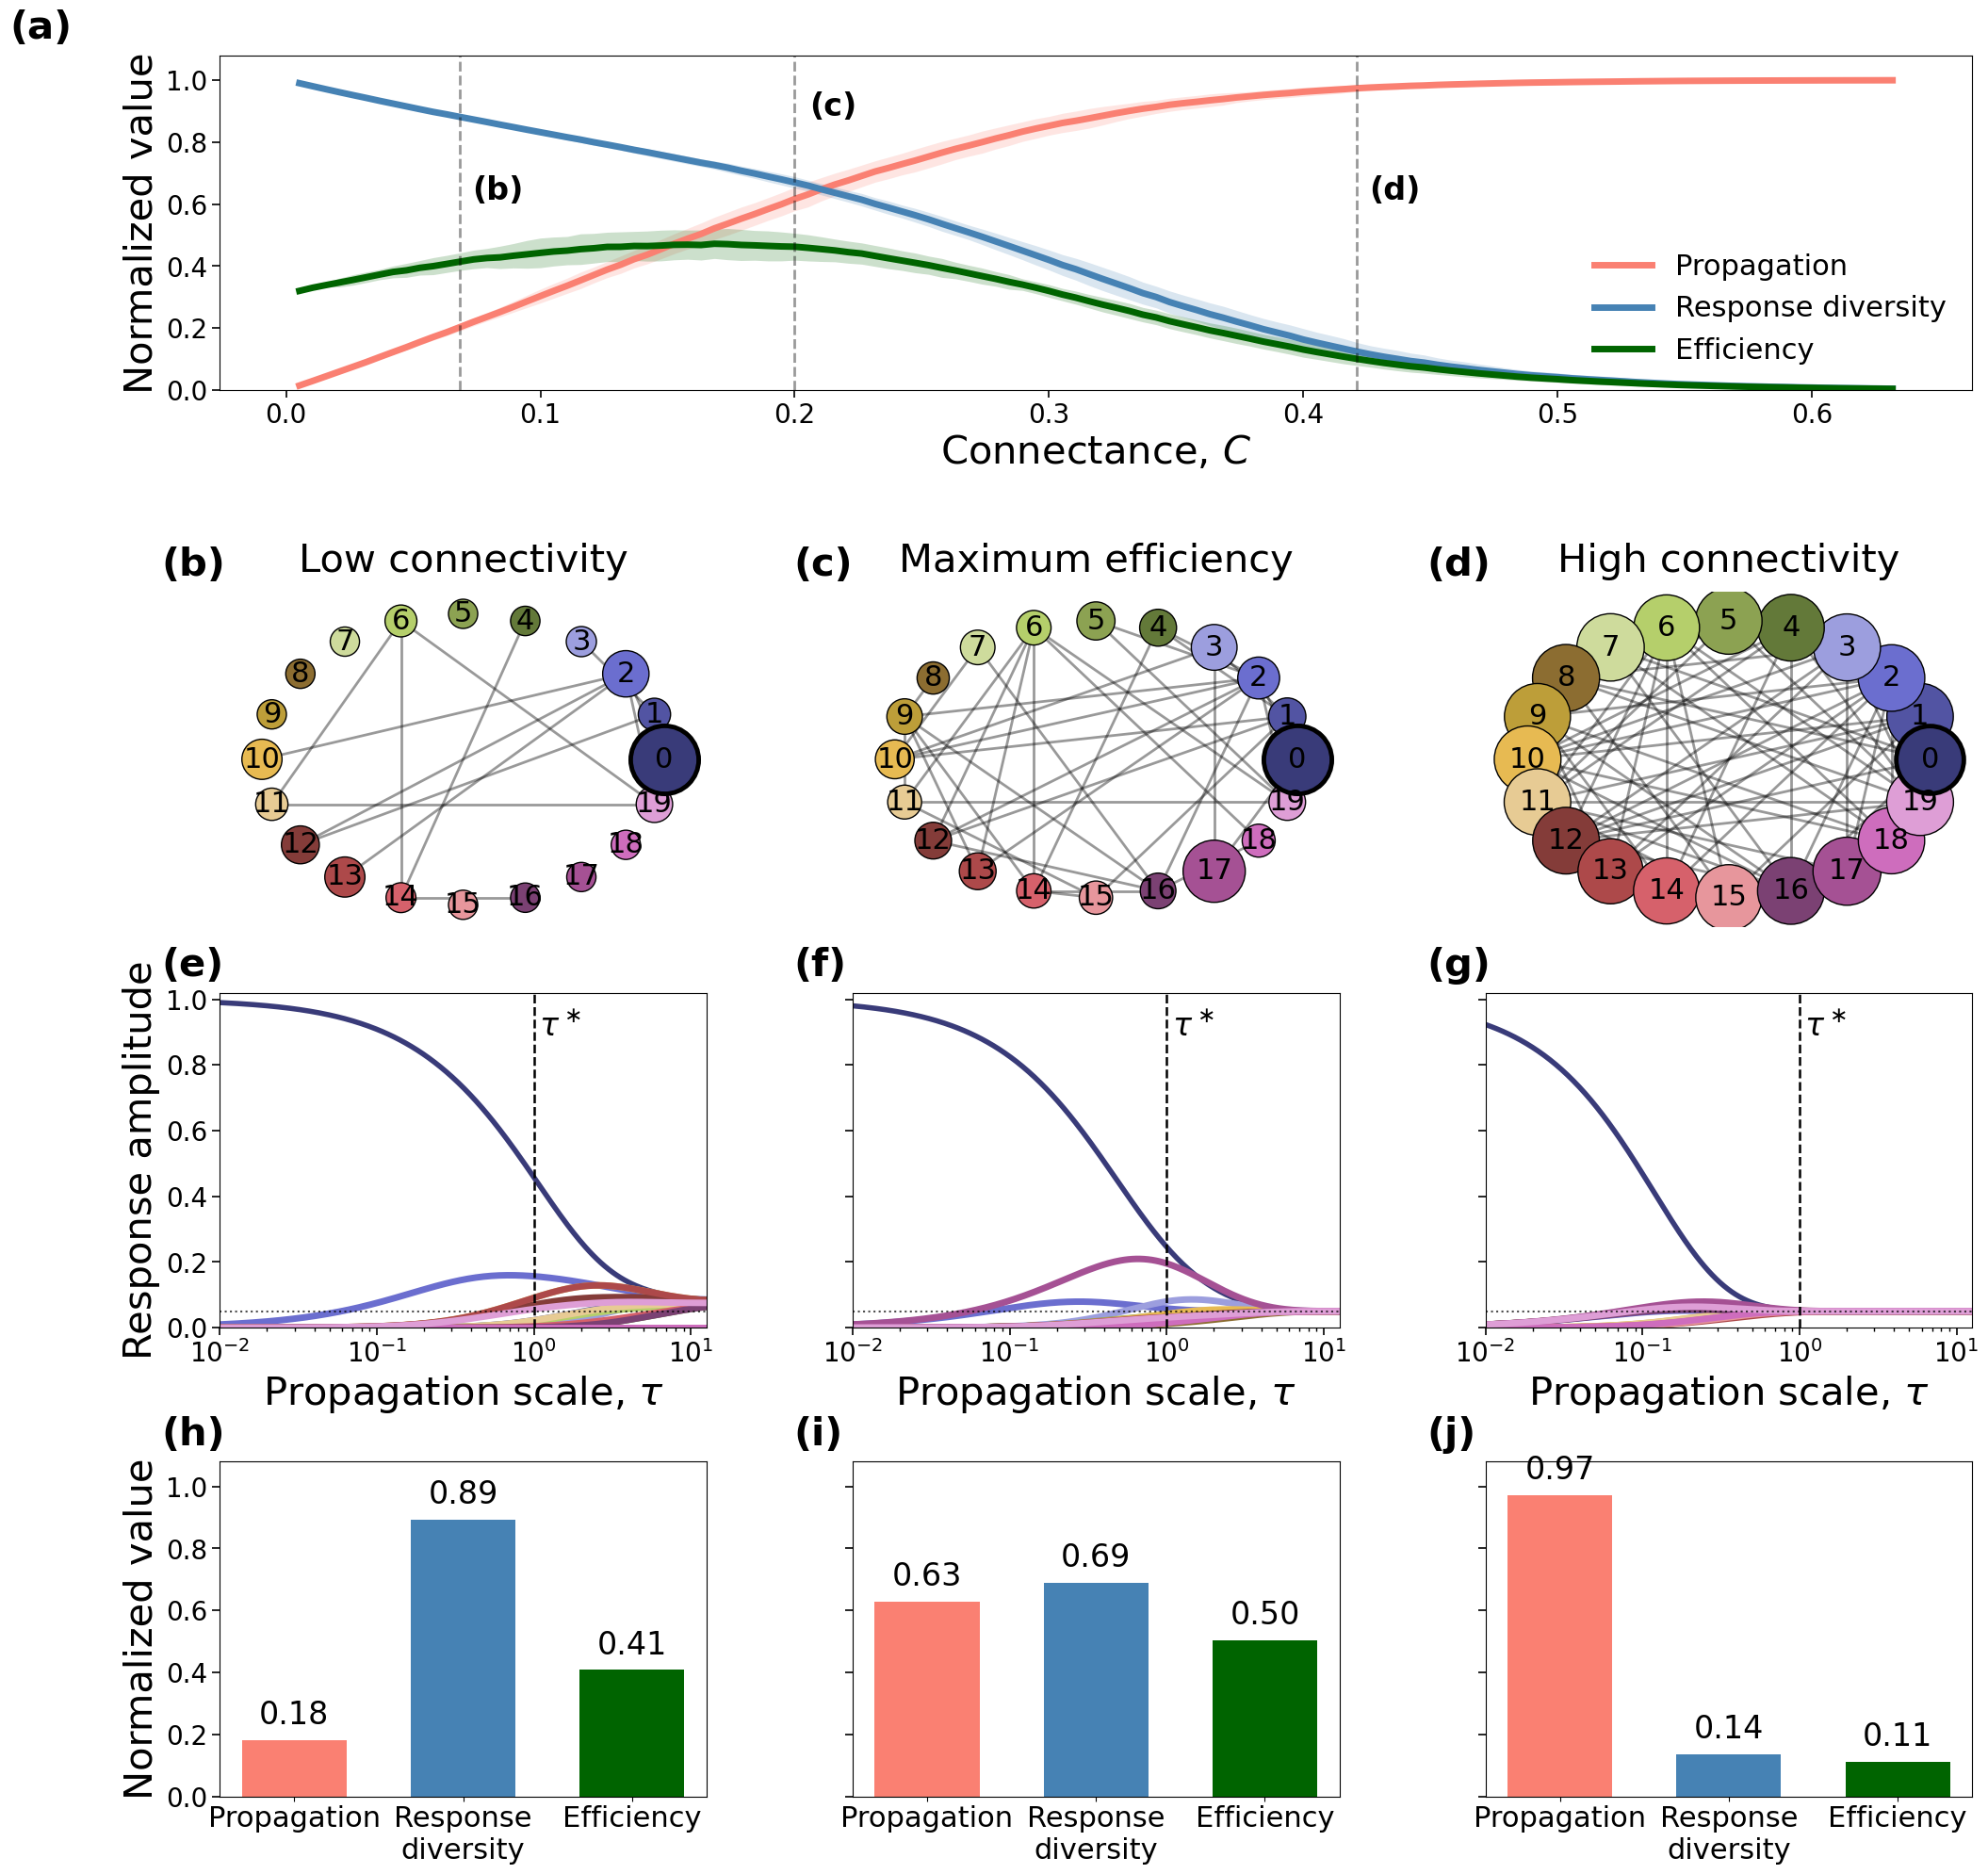

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from network_efficiency_lib import thermo_spectrum


# ============================================================
# 1. Generate ONE nested random-network realization
# ============================================================

def random_network_growth(n=10, seed=397):
    """
    Generate one nested random-network realization.

    Start from N isolated nodes and add all possible edges in a random order.

    Therefore:
        G(L) subset G(L+1)

    and the sparse, optimal and dense networks all belong to exactly the
    same network-growth trajectory.
    """

    rng = np.random.default_rng(seed)

    all_edges = list(nx.complete_graph(n).edges())
    rng.shuffle(all_edges)

    def graph_with_m_edges(m):

        G = nx.Graph()

        G.add_nodes_from(range(n))
        G.add_edges_from(all_edges[:m])

        return G

    return graph_with_m_edges


# ============================================================
# 2. Diffusion from a localized perturbation
# ============================================================

def laplacian_eigendecomposition(G):

    nodes = list(G.nodes())

    A = nx.to_numpy_array(
        G,
        nodelist=nodes,
        dtype=float,
    )

    L = np.diag(A.sum(axis=1)) - A

    eigenvalues, eigenvectors = np.linalg.eigh(L)

    return nodes, eigenvalues, eigenvectors


def diffusion_response(G, source, taus):
    """
    Heat-kernel response

        x(tau) = exp(-tau L) x(0)

    following a perturbation localized at 'source'.

    Returns
    -------
    nodes
    responses : (N, len(taus)) array
    """

    nodes, eigenvalues, eigenvectors = laplacian_eigendecomposition(G)

    index = {
        node: i
        for i, node in enumerate(nodes)
    }

    x0 = np.zeros(len(nodes))
    x0[index[source]] = 1.0

    responses = np.zeros(
        (
            len(nodes),
            len(taus),
        )
    )

    for j, tau in enumerate(taus):

        exponential = np.exp(
            -tau * eigenvalues
        )

        xt = eigenvectors @ (
            exponential
            * (eigenvectors.T @ x0)
        )

        responses[:, j] = xt

    return nodes, responses


# ============================================================
# 3. Thermodynamic quantities
# ============================================================

def normalized_thermodynamic_quantities(G, tau):
    """
    Quantities displayed in the conceptual figure.

    thermo_spectrum returns:

        dS = S_tau - log(N)
        dF = log(N) - log(Z)
        eta

    We plot:

        propagation =
            dF / log(N)

        response diversity =
            S_tau / log(N)
            = (log(N) + dS) / log(N)

        efficiency =
            eta

    All therefore lie on a common 0--1 scale.
    """

    dS, dF, eta = thermo_spectrum(
        G,
        tau,
    )

    logN = np.log(
        G.number_of_nodes()
    )

    propagation = dF / logN

    entropy = logN + dS

    response_diversity = (
        entropy / logN
    )

    return (
        propagation,
        response_diversity,
        eta,
    )


# ============================================================
# 3b. Ensemble thermodynamic quantities vs connectivity
# ============================================================

def thermodynamic_quantities_vs_connectivity(
    n,
    tau_star,
    L_low,
    L_high,
    n_realizations=100,
    seed=1234,
):
    """
    Compute propagation, response diversity and efficiency as a
    function of connectance for multiple independent realizations
    of the same random-network growth process used elsewhere in
    the figure.

    For every realization, links are added in a new random order.

    Returns
    -------
    Dictionary containing:
        - number of links
        - connectance
        - mean propagation +- std
        - mean response diversity +- std
        - mean efficiency +- std
    """

    rng = np.random.default_rng(
        seed
    )

    L_values = np.arange(
        L_low,
        L_high + 1,
    )

    propagation = np.full(
        (
            n_realizations,
            len(L_values),
        ),
        np.nan,
    )

    diversity = np.full(
        (
            n_realizations,
            len(L_values),
        ),
        np.nan,
    )

    efficiency = np.full(
        (
            n_realizations,
            len(L_values),
        ),
        np.nan,
    )

    for r in range(
        n_realizations
    ):

        realization_seed = int(
            rng.integers(
                0,
                1_000_000_000,
            )
        )

        growth = random_network_growth(
            n=n,
            seed=realization_seed,
        )

        for i, L in enumerate(
            L_values
        ):

            G = growth(L)

            try:

                (
                    prop,
                    div,
                    eta,
                ) = normalized_thermodynamic_quantities(
                    G,
                    tau_star,
                )

                if np.isfinite(prop):
                    propagation[r, i] = prop

                if np.isfinite(div):
                    diversity[r, i] = div

                if np.isfinite(eta):
                    efficiency[r, i] = eta

            except Exception:
                pass

    # Undirected connectance:
    #
    # C = 2L / [N(N - 1)]
    #
    connectance = (
        2 * L_values
        / (n * (n - 1))
    )

    return {

        "L_values":
            L_values,

        "connectance":
            connectance,

        "propagation_mean":
            np.nanmean(
                propagation,
                axis=0,
            ),

        "propagation_std":
            np.nanstd(
                propagation,
                axis=0,
            ),

        "diversity_mean":
            np.nanmean(
                diversity,
                axis=0,
            ),

        "diversity_std":
            np.nanstd(
                diversity,
                axis=0,
            ),

        "efficiency_mean":
            np.nanmean(
                efficiency,
                axis=0,
            ),

        "efficiency_std":
            np.nanstd(
                efficiency,
                axis=0,
            ),
    }


# ============================================================
# 4. Select sparse / optimal / dense from ONE realization
# ============================================================

def choose_three_networks(
    n=10,
    tau_star=1.35,
    seed=397,
    L_low=5,
    L_high=30,
):
    """
    User chooses the sparse and dense states.

    The intermediate state is selected automatically as the network
    with maximum thermodynamic efficiency along the SAME realization
    between L_low and L_high.
    """

    L_max = (
        n * (n - 1) // 2
    )

    if L_low < 1:

        raise ValueError(
            "L_low must be at least 1, "
            "because eta is undefined for L=0."
        )

    if L_high > L_max:

        raise ValueError(
            f"For N={n}, the maximum number "
            f"of links is {L_max}."
        )

    if L_low >= L_high:

        raise ValueError(
            "L_low must be smaller than L_high."
        )

    growth = random_network_growth(
        n=n,
        seed=seed,
    )

    # --------------------------------------------------------
    # Find maximum efficiency along this single realization
    # --------------------------------------------------------

    L_values = np.arange(
        L_low,
        L_high + 1,
    )

    eta_values = np.full(
        len(L_values),
        np.nan,
    )

    for i, L in enumerate(
        L_values
    ):

        G = growth(L)

        try:

            _, _, eta = thermo_spectrum(
                G,
                tau_star,
            )

            if np.isfinite(eta):

                eta_values[i] = eta

        except Exception:
            pass

    if np.all(
        np.isnan(eta_values)
    ):

        raise RuntimeError(
            "No valid efficiency values found."
        )

    i_opt = np.nanargmax(
        eta_values
    )

    L_opt = L_values[i_opt]

    G_low = growth(
        L_low
    )

    G_opt = growth(
        L_opt
    )

    G_high = growth(
        L_high
    )

    return (
        [
            G_low,
            G_opt,
            G_high,
        ],
        [
            L_low,
            L_opt,
            L_high,
        ],
        L_values,
        eta_values,
    )


# ============================================================
# 5. Figure
# ============================================================

def make_thermodynamic_concept_figure(
    n=10,
    source=0,
    tau_star=1.35,
    seed=397,
    L_low=5,               # low example network
    L_high=30,             # high example network
    L_summary_low=1,       # start of panel (a)
    L_summary_high=None,   # end of panel (a)
    n_realizations=100,
    savepath=None,
):

    (
        graphs,
        edge_counts,
        L_values,
        eta_values,
    ) = choose_three_networks(
        n=n,
        tau_star=tau_star,
        seed=seed,
        L_low=L_low,
        L_high=L_high,
    )

    column_titles = [
        "Low connectivity",
        "Maximum efficiency",
        "High connectivity",
    ]

    # ========================================================
    # Plotting parameters
    # ========================================================

    fs_title = 30
    fs_label = 30
    fs_tick = 20
    fs_node = 22
    fs_value = 24
    fs_annotation = 24
    fs_legend = 22

    lw_response = 5
    lw_source = 4

    propagation_color = "salmon"
    diversity_color = "steelblue"
    eta_color = "darkgreen"

    # ========================================================
    # Node colors
    # ========================================================

    # colors = plt.cm.tab20.colors

    # Use vanimo color palette for better contrast from plt.cm.vanimo.colors
    colors = plt.cm.get_cmap("tab20b", 20).colors

    node_color = {
        node: colors[
            node % len(colors)
        ]
        for node in range(n)
    }

    # Same positions in all three networks.
    pos = nx.circular_layout(
        graphs[1]
    )

    # ========================================================
    # Response through time
    # ========================================================

    taus = np.logspace(
        -2,
        1.1,
        250,
    )

    all_responses = []

    for G in graphs:

        nodes, responses = diffusion_response(
            G,
            source=source,
            taus=taus,
        )

        all_responses.append(
            (
                nodes,
                responses,
            )
        )

    # Response at tau_star for node sizes
    # in network diagrams.
    tau_idx = np.argmin(
        np.abs(
            taus - tau_star
        )
    )

    # ========================================================
    # Thermodynamic quantities for the example networks
    # ========================================================

    thermo = [

        normalized_thermodynamic_quantities(
            G,
            tau_star,
        )

        for G in graphs
    ]

    # ========================================================
    # Ensemble thermodynamic curves
    # ========================================================
    
    L_max_possible = n * (n - 1) // 2

    if L_summary_high is None:
        L_summary_high = L_max_possible

    thermo_ensemble = thermodynamic_quantities_vs_connectivity(
        n=n,
        tau_star=tau_star,
        L_low=L_summary_low,
        L_high=L_summary_high,
        n_realizations=n_realizations,
        seed=seed + 1000,
    )

    # ========================================================
    # Figure using subplot_mosaic
    # ========================================================

    mosaic = [
        ["summary",      "summary",      "summary"],
        ["network_low",  "network_opt",  "network_high"],
        ["response_low", "response_opt", "response_high"],
        ["thermo_low",   "thermo_opt",   "thermo_high"],
    ]

    fig, axd = plt.subplot_mosaic(
        mosaic,
        figsize=(
            8 * 3,
            6 * 4,
        ),
        gridspec_kw={
            "hspace": 0.4,
            "wspace": 0.3,
        },
    )

    summary_ax = axd[
        "summary"
    ]

    network_axes = [
        axd["network_low"],
        axd["network_opt"],
        axd["network_high"],
    ]

    response_axes = [
        axd["response_low"],
        axd["response_opt"],
        axd["response_high"],
    ]

    thermo_axes = [
        axd["thermo_low"],
        axd["thermo_opt"],
        axd["thermo_high"],
    ]

    # ========================================================
    # Panel (a): thermodynamic trade-off vs connectance
    # ========================================================

    C = thermo_ensemble[
        "connectance"
    ]

    # --------------------------------------------------------
    # Propagation
    # --------------------------------------------------------

    propagation_mean = (
        thermo_ensemble[
            "propagation_mean"
        ]
    )

    propagation_std = (
        thermo_ensemble[
            "propagation_std"
        ]
    )

    summary_ax.plot(
        C,
        propagation_mean,
        color=propagation_color,
        linewidth=5,
        label="Propagation",
    )

    summary_ax.fill_between(
        C,
        propagation_mean
        - propagation_std,
        propagation_mean
        + propagation_std,
        color=propagation_color,
        alpha=0.20,
        linewidth=0,
    )

    # --------------------------------------------------------
    # Response diversity
    # --------------------------------------------------------

    diversity_mean = (
        thermo_ensemble[
            "diversity_mean"
        ]
    )

    diversity_std = (
        thermo_ensemble[
            "diversity_std"
        ]
    )

    summary_ax.plot(
        C,
        diversity_mean,
        color=diversity_color,
        linewidth=5,
        label="Response diversity",
    )

    summary_ax.fill_between(
        C,
        diversity_mean
        - diversity_std,
        diversity_mean
        + diversity_std,
        color=diversity_color,
        alpha=0.20,
        linewidth=0,
    )

    # --------------------------------------------------------
    # Efficiency
    # --------------------------------------------------------

    efficiency_mean = (
        thermo_ensemble[
            "efficiency_mean"
        ]
    )

    efficiency_std = (
        thermo_ensemble[
            "efficiency_std"
        ]
    )

    summary_ax.plot(
        C,
        efficiency_mean,
        color=eta_color,
        linewidth=5,
        label="Efficiency",
    )

    summary_ax.fill_between(
        C,
        efficiency_mean
        - efficiency_std,
        efficiency_mean
        + efficiency_std,
        color=eta_color,
        alpha=0.20,
        linewidth=0,
    )

    # --------------------------------------------------------
    # Mark the three specific example networks
    # --------------------------------------------------------

    L_max_possible = (
        n * (n - 1) / 2
    )

    example_connectances = (
        np.asarray(
            edge_counts
        )
        / L_max_possible
    )

    example_labels = [
        "(b)",
        "(c)",
        "(d)",
    ]

    for (
        C_example,
        example_label,
    ) in zip(
        example_connectances,
        example_labels,
    ):
        if example_label == "(c)":
            y_coord = 0.8
        else:
            y_coord = 0.55

        summary_ax.axvline(
            C_example,
            color="k",
            linestyle="--",
            linewidth=2,
            alpha=0.40,
        )

        summary_ax.text(
            C_example+0.015,
            y_coord,
            example_label,
            transform=summary_ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            weight="bold",
            fontsize=fs_annotation,
        )

    # --------------------------------------------------------
    # Summary panel formatting
    # --------------------------------------------------------

    summary_ax.set_ylim(
        0,
        1.08,
    )

    summary_ax.set_xlabel(
        r"Connectance, $C$",
        fontsize=fs_label,
    )

    summary_ax.set_ylabel(
        "Normalized value",
        fontsize=fs_label,
    )

    summary_ax.tick_params(
        axis="both",
        which="major",
        labelsize=fs_tick,
        width=1.2,
        length=6,
    )

    summary_ax.tick_params(
        axis="both",
        which="minor",
        labelsize=fs_tick,
        width=1.0,
        length=3,
    )

    summary_ax.legend(
        frameon=False,
        fontsize=fs_legend,
        loc="best",
    )

    # ========================================================
    # Panels (b-d), row 1:
    # network topology + perturbation state
    # ========================================================

    for col, (
        ax,
        G,
        L,
        title,
    ) in enumerate(
        zip(
            network_axes,
            graphs,
            edge_counts,
            column_titles,
        )
    ):

        nodes, responses = (
            all_responses[col]
        )

        snapshot = responses[
            :,
            tau_idx,
        ]

        # Response amplitude controls node size.
        # Node color identifies node identity.
        node_sizes = (
            500
            + 2200
            * snapshot
            / np.max(snapshot)
        )

        nx.draw_networkx_edges(
            G,
            pos,
            ax=ax,
            width=2.0,
            alpha=0.40,
        )

        nx.draw_networkx_nodes(
            G,
            pos,
            ax=ax,
            nodelist=nodes,
            node_color=[
                node_color[node]
                for node in nodes
            ],
            node_size=node_sizes,
            edgecolors="black",
            linewidths=1.0,
        )

        # Emphasize perturbed/source node.
        nx.draw_networkx_nodes(
            G,
            pos,
            ax=ax,
            nodelist=[
                source
            ],
            node_color=[
                node_color[source]
            ],
            node_size=[
                node_sizes[
                    nodes.index(source)
                ]
            ],
            edgecolors="black",
            linewidths=3.5,
        )

        nx.draw_networkx_labels(
            G,
            pos,
            labels={
                node: str(node)
                for node in nodes
            },
            font_size=fs_node,
            ax=ax,
        )

        ax.set_title(
            title,
            fontsize=fs_title,
            pad=15,
        )

        ax.set_axis_off()

    # ========================================================
    # Panels (b-d), row 2:
    # response of all nodes
    # ========================================================

    response_max = max(
        np.max(responses)
        for _, responses
        in all_responses
    )

    for col, (
        ax,
        (
            nodes,
            responses,
        ),
    ) in enumerate(
        zip(
            response_axes,
            all_responses,
        )
    ):

        for i, node in enumerate(
            nodes
        ):

            linewidth = (
                lw_source
                if node == source
                else lw_response
            )

            ax.plot(
                taus,
                responses[i],
                color=node_color[node],
                linewidth=linewidth,
                label=f"Node {node}",
            )

        ax.axvline(
            tau_star,
            linestyle="--",
            linewidth=1.8,
            color="k",
        )

        # Equilibrium response for a connected network.
        ax.axhline(
            1 / n,
            linestyle=":",
            linewidth=1.5,
            color="k",
            alpha=0.7,
        )

        ax.set_xscale(
            "log"
        )

        ax.set_xlim(
            taus.min(),
            taus.max(),
        )

        ax.set_ylim(
            0,
            response_max * 1.03,
        )

        ax.set_xlabel(
            r"Propagation scale, $\tau$",
            fontsize=fs_label,
        )

        if col == 0:

            ax.set_ylabel(
                "Response amplitude",
                fontsize=fs_label,
            )

        else:

            ax.set_yticklabels(
                []
            )

        ax.tick_params(
            axis="both",
            which="major",
            labelsize=fs_tick,
            width=1.2,
            length=6,
        )

        ax.tick_params(
            axis="both",
            which="minor",
            labelsize=fs_tick,
            width=1.0,
            length=3,
        )

        ax.text(
            tau_star * 1.08,
            response_max * 0.90,
            r"$\tau^\ast$",
            fontsize=fs_annotation,
        )

    # ========================================================
    # Panels (b-d), row 3:
    # thermodynamic balance
    # ========================================================

    labels = [
        "Propagation",
        "Response\ndiversity",
        "Efficiency",
    ]

    x = np.arange(3)

    for col, (
        ax,
        values,
    ) in enumerate(
        zip(
            thermo_axes,
            thermo,
        )
    ):

        (
            propagation,
            diversity,
            eta,
        ) = values

        ax.bar(
            x[0],
            propagation,
            width=0.62,
            color=propagation_color,
        )

        ax.bar(
            x[1],
            diversity,
            width=0.62,
            color=diversity_color,
        )

        ax.bar(
            x[2],
            eta,
            width=0.62,
            color=eta_color,
        )

        bars = [
            propagation,
            diversity,
            eta,
        ]

        ax.set_ylim(
            0,
            1.08,
        )

        ax.set_xticks(
            x
        )

        ax.set_xticklabels(
            labels,
            fontsize=22,
        )

        if col == 0:

            ax.set_ylabel(
                "Normalized value",
                fontsize=fs_label,
            )

        else:

            ax.set_yticklabels(
                []
            )

        ax.tick_params(
            axis="y",
            which="major",
            labelsize=fs_tick,
            width=1.2,
            length=6,
        )

        # Numerical values above bars.
        for xi, value in zip(
            x,
            bars,
        ):

            ax.text(
                xi,
                value + 0.03,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=fs_value,
            )
            
    for ax in network_axes:
        box = ax.get_position()

        ax.set_position([
            box.x0,
            box.y0 - 0.03,   # move downward
            box.width,
            box.height,
        ])
        
    # ========================================================
    # Label panels
    # ========================================================

    for ax, label in zip(
        [
            summary_ax,
            *network_axes,
            *response_axes,
            *thermo_axes,
        ],
        [
            "(a)",
            "(b)",
            "(c)",
            "(d)",
            "(e)",
            "(f)",
            "(g)",
            "(h)",
            "(i)",
            "(j)",
            "(k)",
            "(l)",
        ],
    ):

        ax.text(
            -0.12,
            1.05,
            label,
            transform=ax.transAxes,
            fontsize=fs_title,
            fontweight="bold",
        )

    # ========================================================
    # Save
    # ========================================================

    if savepath is not None:

        fig.savefig(
            savepath,
            bbox_inches="tight",
            dpi=300,
        )

    return fig, {

        "graphs":
            graphs,

        "edge_counts":
            edge_counts,

        "L_values":
            L_values,

        "eta_values":
            eta_values,

        "thermodynamic_values":
            thermo,

        "thermodynamic_ensemble":
            thermo_ensemble,

        "tau_star":
            tau_star,
    }


# ============================================================
# Generate figure
# ============================================================

fig, data = make_thermodynamic_concept_figure(
    n=20,
    source=0,
    tau_star=1,

    # Example networks
    L_low=13,
    L_high=80,

    # Broader range shown in panel (a)
    L_summary_low=1,
    L_summary_high=120,

    n_realizations=100,

    savepath=None, # Change to save the figure
)

plt.show()